# TASK - 02
## DATA CLEANING & FEATURE ENGINEERING

## RETAIL-STORE SALES DATASET

### UPLOAD DATASET

In [ ]:
# Upload .csv file
import pandas as pd
import numpy as np
from google.colab import files

uploaded = files.upload()

Saving retail_store_sales(in).csv to retail_store_sales(in).csv


### INSPECT THE DATASET

In [ ]:
# Load the CSV file
filename = next(iter(uploaded))
df = pd.read_csv(filename)

# 1. Dataset size
print("Dataset shape:", df.shape)

# 2. Column names
print("\nColumn names:")
print(df.columns.tolist())

# 3. Missing values in each column
print("\nMissing values:")
print(df.isnull().sum())

# 4. Duplicate records
print("\nDuplicate rows:", df.duplicated().sum())

# 5. First five records
print("\nFirst five records:")
display(df.head())

# 6. Data types
print("\nData types:")
print(df.dtypes)

# 7. Basic descriptive statistics
print("\nDescriptive statistics:")
display(df.describe(include="all").T)

Dataset shape: (12575, 11)

Column names:
['Transaction ID', 'Customer ID', 'Category', 'Item', 'Price Per Unit', 'Quantity', 'Total Spent', 'Payment Method', 'Location', 'Transaction Date', 'Discount Applied']

Missing values:
Transaction ID         0
Customer ID            0
Category               0
Item                1213
Price Per Unit       609
Quantity             604
Total Spent          604
Payment Method         0
Location               0
Transaction Date       0
Discount Applied    4199
dtype: int64

Duplicate rows: 0

First five records:


,Transaction ID,Customer ID,Category,Item,Price Per Unit,Quantity,Total Spent,Payment Method,Location,Transaction Date,Discount Applied
0,TXN_6867343,CUST_09,Patisserie,Item_10_PAT,18.5,10.0,185.0,Digital Wallet,Online,4/8/2024,True
1,TXN_3731986,CUST_22,Milk Products,Item_17_MILK,29.0,9.0,261.0,Digital Wallet,Online,7/23/2023,True
2,TXN_9303719,CUST_02,Butchers,Item_12_BUT,21.5,2.0,43.0,Credit Card,Online,10/5/2022,False
3,TXN_9458126,CUST_06,Beverages,Item_16_BEV,27.5,9.0,247.5,Credit Card,Online,5/7/2022,NaN
4,TXN_4575373,CUST_05,Food,Item_6_FOOD,12.5,7.0,87.5,Digital Wallet,Online,10/2/2022,False



Data types:
Transaction ID       object
Customer ID          object
Category             object
Item                 object
Price Per Unit      float64
Quantity            float64
Total Spent         float64
Payment Method       object
Location             object
Transaction Date     object
Discount Applied     object
dtype: object

Descriptive statistics:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Transaction ID,12575,12575,TXN_2407494,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Customer ID,12575,25,CUST_05,544,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Category,12575,8,Electric household essentials,1591,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Item,11362,200,Item_2_BEV,126,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Price Per Unit,11966.0,NaN,NaN,NaN,23.365912,10.743519,5.0,14.0,23.0,33.5,41.0
Quantity,11971.0,NaN,NaN,NaN,5.53638,2.857883,1.0,3.0,6.0,8.0,10.0
Total Spent,11971.0,NaN,NaN,NaN,129.652577,94.750697,5.0,51.0,108.5,192.0,410.0
Payment Method,12575,3,Cash,4310,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Location,12575,2,Online,6354,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Transaction Date,12575,1114,5/30/2022,26,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### IDENTIFY MISSING VALUES

In [ ]:
# Missing values and percentages
missing_summary = pd.DataFrame({
    "Missing Count": df.isnull().sum(),
    "Missing Percentage": (df.isnull().mean() * 100).round(2)
})

print("Missing Value Summary:")
display(missing_summary)

# Check whether Total Spent matches Price Per Unit × Quantity
valid_rows = df[
    ["Price Per Unit", "Quantity", "Total Spent"]
].notna().all(axis=1)

expected_total = (
    df.loc[valid_rows, "Price Per Unit"]
    * df.loc[valid_rows, "Quantity"]
)

difference = (
    df.loc[valid_rows, "Total Spent"] - expected_total
).abs()

print("\nRows with all three numerical values:", valid_rows.sum())
print("Rows where Total Spent does not match price × quantity:",
      (difference > 0.01).sum())

# Check numeric ranges
print("\nNumerical column ranges:")
display(df[["Price Per Unit", "Quantity", "Total Spent"]].agg(["min", "max"]))

# Check unique categorical values
for column in ["Category", "Payment Method", "Location", "Discount Applied"]:
    print(f"\nUnique values in {column}:")
    print(df[column].value_counts(dropna=False))

# Check transaction date conversion without changing the original
parsed_dates = pd.to_datetime(
    df["Transaction Date"], errors="coerce"
)

print("\nInvalid transaction dates:", parsed_dates.isna().sum())
print("Earliest transaction date:", parsed_dates.min())
print("Latest transaction date:", parsed_dates.max())


Missing Value Summary:


,Missing Count,Missing Percentage
Transaction ID,0,0.00
Customer ID,0,0.00
Category,0,0.00
Item,1213,9.65
Price Per Unit,609,4.84
Quantity,604,4.80
Total Spent,604,4.80
Payment Method,0,0.00
Location,0,0.00
Transaction Date,0,0.00



Rows with all three numerical values: 11362
Rows where Total Spent does not match price × quantity: 0

Numerical column ranges:


,Price Per Unit,Quantity,Total Spent
min,5.0,1.0,5.0
max,41.0,10.0,410.0



Unique values in Category:
Category
Electric household essentials         1591
Furniture                             1591
Food                                  1588
Milk Products                         1584
Butchers                              1568
Beverages                             1567
Computers and electric accessories    1558
Patisserie                            1528
Name: count, dtype: int64

Unique values in Payment Method:
Payment Method
Cash              4310
Digital Wallet    4144
Credit Card       4121
Name: count, dtype: int64

Unique values in Location:
Location
Online      6354
In-store    6221
Name: count, dtype: int64

Unique values in Discount Applied:
Discount Applied
True     4219
NaN      4199
False    4157
Name: count, dtype: int64

Invalid transaction dates: 0
Earliest transaction date: 2022-01-01 00:00:00
Latest transaction date: 2025-01-18 00:00:00


### HANDLE MISSING VALUES

In [ ]:
# Keep the original dataset unchanged
df_clean = df.copy()

# Convert transaction dates to datetime
df_clean["Transaction Date"] = pd.to_datetime(
    df_clean["Transaction Date"],
    errors="coerce"
)

Fill missing item names
df_clean["Item"] = df_clean["Item"].fillna("Unknown")

# Fill missing numerical values using the median
df_clean["Price Per Unit"] = df_clean["Price Per Unit"].fillna(
    df_clean["Price Per Unit"].median()
)

df_clean["Quantity"] = df_clean["Quantity"].fillna(
    df_clean["Quantity"].median()
)

# Calculate missing totals where possible
calculated_total = (
    df_clean["Price Per Unit"] * df_clean["Quantity"]
)

df_clean["Total Spent"] = df_clean["Total Spent"].fillna(
    calculated_total
)

# Fallback in case any totals remain missing
df_clean["Total Spent"] = df_clean["Total Spent"].fillna(
    df_clean["Total Spent"].median()
)

# Preserve unknown discount status as a separate category
df_clean["Discount Applied"] = (
    df_clean["Discount Applied"].astype("object").fillna("Unknown")
)

# Compare missing values before and after cleaning
print("Missing values BEFORE cleaning:")
display(df.isnull().sum().to_frame("Missing Before"))

print("\nMissing values AFTER cleaning:")
display(df_clean.isnull().sum().to_frame("Missing After"))

print("\nCleaned dataset shape:", df_clean.shape)
print("Duplicate rows:", df_clean.duplicated().sum())

print("\nDescriptive statistics AFTER cleaning:")
display(df_clean.describe(include="all").T)


Missing values BEFORE cleaning:


,Missing Before
Transaction ID,0
Customer ID,0
Category,0
Item,1213
Price Per Unit,609
Quantity,604
Total Spent,604
Payment Method,0
Location,0
Transaction Date,0



Missing values AFTER cleaning:


,Missing After
Transaction ID,0
Customer ID,0
Category,0
Item,0
Price Per Unit,0
Quantity,0
Total Spent,0
Payment Method,0
Location,0
Transaction Date,0



Cleaned dataset shape: (12575, 11)
Duplicate rows: 0

Descriptive statistics AFTER cleaning:


,count,unique,top,freq,mean,min,25%,50%,75%,max,std
Transaction ID,12575,12575,TXN_2407494,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Customer ID,12575,25,CUST_05,544,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Category,12575,8,Electric household essentials,1591,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Item,12575,201,Unknown,1213,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Price Per Unit,12575.0,NaN,NaN,NaN,23.348191,5.0,14.0,23.0,32.0,41.0,10.480413
Quantity,12575.0,NaN,NaN,NaN,5.558648,1.0,3.0,6.0,8.0,10.0,2.79016
Total Spent,12575.0,NaN,NaN,NaN,130.208111,5.0,52.0,110.0,192.0,410.0,93.580667
Payment Method,12575,3,Cash,4310,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Location,12575,2,Online,6354,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Transaction Date,12575,NaN,NaN,NaN,2023-07-12 20:23:41.105368064,2022-01-01 00:00:00,2022-09-30 00:00:00,2023-07-13 00:00:00,2024-04-24 00:00:00,2025-01-18 00:00:00,NaN


### DETECT OUTLIERS

In [ ]:
# Detect outliers using the IQR method

numerical_columns = [
    "Price Per Unit",
    "Quantity",
    "Total Spent"
]

outlier_results = []

for column in numerical_columns:
    Q1 = df_clean[column].quantile(0.25)
    Q3 = df_clean[column].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    # Identify values outside the IQR boundaries

    outlier_mask = (
        (df_clean[column] < lower_bound) |
        (df_clean[column] > upper_bound)
    )

    outlier_results.append({
        "Column": column,
        "Q1": Q1,
        "Q3": Q3,
        "IQR": IQR,
        "Lower Bound": lower_bound,
        "Upper Bound": upper_bound,
        "Outlier Count": outlier_mask.sum()
    })

outlier_summary = pd.DataFrame(outlier_results)

print("Outlier Detection Summary:")
display(outlier_summary.round(2))

Outlier Detection Summary:


,Column,Q1,Q3,IQR,Lower Bound,Upper Bound,Outlier Count
0,Price Per Unit,14.0,32.0,18.0,-13.0,59.0,0
1,Quantity,3.0,8.0,5.0,-4.5,15.5,0
2,Total Spent,52.0,192.0,140.0,-158.0,402.0,60


### VISUALIZE OUTLIERS

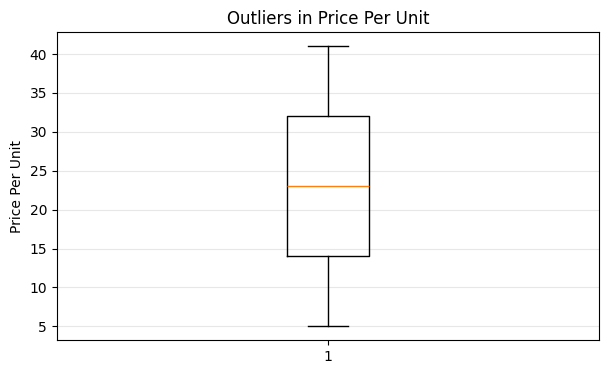

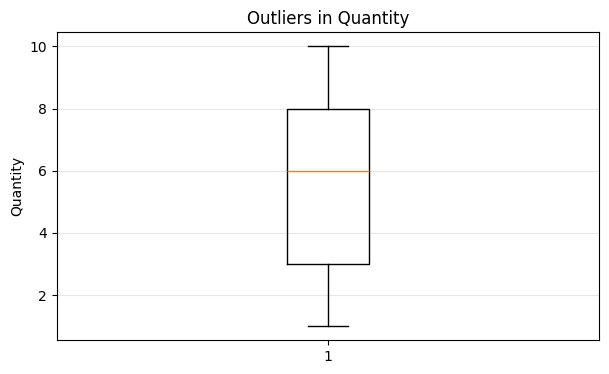

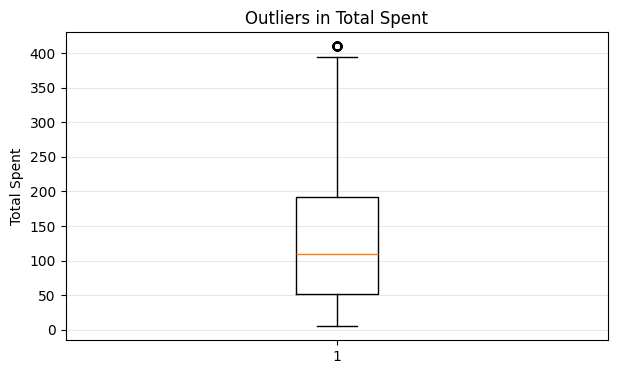

In [ ]:
import matplotlib.pyplot as plt

for column in numerical_columns:
    plt.figure(figsize=(7, 4))
    plt.boxplot(df_clean[column])
    plt.title(f"Outliers in {column}")
    plt.ylabel(column)
    plt.grid(axis="y", alpha=0.3)
    plt.show()


### INVESTIGATE AND HANDLE OUTLIERS
#### 1. Investigate Potintial Outliers

In [ ]:
# Investigate potential outliers

Q1 = df_clean["Total Spent"].quantile(0.25)
Q3 = df_clean["Total Spent"].quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outlier_mask = (
    (df_clean["Total Spent"] < lower_bound) |
    (df_clean["Total Spent"] > upper_bound)
)

outliers = df_clean.loc[
    outlier_mask,
    [
        "Transaction ID",
        "Category",
        "Item",
        "Price Per Unit",
        "Quantity",
        "Total Spent"
    ]
]

print("Potential outliers:", len(outliers))
print("Minimum flagged total:", outliers["Total Spent"].min())
print("Maximum flagged total:", outliers["Total Spent"].max())

display(outliers.head(15))

Potential outliers: 60
Minimum flagged total: 410.0
Maximum flagged total: 410.0


,Transaction ID,Category,Item,Price Per Unit,Quantity,Total Spent
27,TXN_1599706,Furniture,Item_25_FUR,41.0,10.0,410.0
133,TXN_2953434,Furniture,Item_25_FUR,41.0,10.0,410.0
339,TXN_4374445,Food,Item_25_FOOD,41.0,10.0,410.0
869,TXN_1814138,Beverages,Item_25_BEV,41.0,10.0,410.0
1060,TXN_3710081,Furniture,Item_25_FUR,41.0,10.0,410.0
1088,TXN_1273334,Beverages,Item_25_BEV,41.0,10.0,410.0
1468,TXN_1938135,Butchers,Item_25_BUT,41.0,10.0,410.0
1505,TXN_8520397,Electric household essentials,Item_25_EHE,41.0,10.0,410.0
1568,TXN_8048041,Butchers,Item_25_BUT,41.0,10.0,410.0
1950,TXN_1860120,Furniture,Item_25_FUR,41.0,10.0,410.0


#### 2. Check Whether the Flagged Totals are Consistent

In [ ]:
# Check whether outlier totals match price × quantity

outlier_check = outliers.copy()

outlier_check["Expected Total"] = (
    outlier_check["Price Per Unit"] *
    outlier_check["Quantity"]
)

outlier_check["Matches Calculation"] = np.isclose(
    outlier_check["Total Spent"],
    outlier_check["Expected Total"]
)

display(outlier_check.head(15))

print(
    "Flagged records that match price × quantity:",
    outlier_check["Matches Calculation"].sum(),
    "out of",
    len(outlier_check)
)


,Transaction ID,Category,Item,Price Per Unit,Quantity,Total Spent,Expected Total,Matches Calculation
27,TXN_1599706,Furniture,Item_25_FUR,41.0,10.0,410.0,410.0,True
133,TXN_2953434,Furniture,Item_25_FUR,41.0,10.0,410.0,410.0,True
339,TXN_4374445,Food,Item_25_FOOD,41.0,10.0,410.0,410.0,True
869,TXN_1814138,Beverages,Item_25_BEV,41.0,10.0,410.0,410.0,True
1060,TXN_3710081,Furniture,Item_25_FUR,41.0,10.0,410.0,410.0,True
1088,TXN_1273334,Beverages,Item_25_BEV,41.0,10.0,410.0,410.0,True
1468,TXN_1938135,Butchers,Item_25_BUT,41.0,10.0,410.0,410.0,True
1505,TXN_8520397,Electric household essentials,Item_25_EHE,41.0,10.0,410.0,410.0,True
1568,TXN_8048041,Butchers,Item_25_BUT,41.0,10.0,410.0,410.0,True
1950,TXN_1860120,Furniture,Item_25_FUR,41.0,10.0,410.0,410.0,True


Flagged records that match price × quantity: 56 out of 60


In [ ]:
# Find flagged records whose totals don't match price × quantity
outlier_check = outliers.copy()

outlier_check["Expected Total"] = (
    outlier_check["Price Per Unit"] * outlier_check["Quantity"]
)

outlier_check["Matches Calculation"] = np.isclose(
    outlier_check["Total Spent"],
    outlier_check["Expected Total"]
)

# Display only inconsistent records
display(
    outlier_check[
        outlier_check["Matches Calculation"] == False
    ]
)

,Transaction ID,Category,Item,Price Per Unit,Quantity,Total Spent,Expected Total,Matches Calculation
2153,TXN_5338814,Milk Products,Unknown,23.0,10.0,410.0,230.0,False
5745,TXN_3855536,Computers and electric accessories,Unknown,23.0,10.0,410.0,230.0,False
8508,TXN_4771109,Electric household essentials,Unknown,23.0,10.0,410.0,230.0,False
8596,TXN_2288041,Food,Unknown,23.0,10.0,410.0,230.0,False


### CONVERT INCORRECT DATA TYPES
#### 1. Check Data Types

In [ ]:
# Check data types before conversion
print("Data types before conversion:")
print(df_clean.dtypes)

Data types before conversion:
Transaction ID              object
Customer ID                 object
Category                    object
Item                        object
Price Per Unit             float64
Quantity                   float64
Total Spent                float64
Payment Method              object
Location                    object
Transaction Date    datetime64[ns]
Discount Applied            object
dtype: object


#### 2. Updated Data Types

In [ ]:
# Ensure transaction dates use datetime format
df_clean["Transaction Date"] = pd.to_datetime(
    df_clean["Transaction Date"],
    errors="coerce"
)

# Convert transaction and customer IDs to text
df_clean["Transaction ID"] = df_clean["Transaction ID"].astype("string")
df_clean["Customer ID"] = df_clean["Customer ID"].astype("string")

# Display updated data types
print("Data types after conversion:")
print(df_clean.dtypes)

Data types after conversion:
Transaction ID      string[python]
Customer ID         string[python]
Category                    object
Item                        object
Price Per Unit             float64
Quantity                   float64
Total Spent                float64
Payment Method              object
Location                    object
Transaction Date    datetime64[ns]
Discount Applied            object
dtype: object


#### Inconsistent Transactions

In [ ]:
# Inspect the four inconsistent transactions in the original data
problem_ids = [
    "TXN_5338814",
    "TXN_3855536",
    "TXN_4771109",
    "TXN_2288041"
]

original_records = df[
    df["Transaction ID"].isin(problem_ids)
]

display(original_records)

,Transaction ID,Customer ID,Category,Item,Price Per Unit,Quantity,Total Spent,Payment Method,Location,Transaction Date,Discount Applied
2153,TXN_5338814,CUST_06,Milk Products,NaN,NaN,10.0,410.0,Digital Wallet,Online,3/13/2023,False
5745,TXN_3855536,CUST_04,Computers and electric accessories,NaN,NaN,10.0,410.0,Credit Card,In-store,9/27/2024,True
8508,TXN_4771109,CUST_21,Electric household essentials,NaN,NaN,10.0,410.0,Digital Wallet,In-store,7/3/2022,True
8596,TXN_2288041,CUST_24,Food,NaN,NaN,10.0,410.0,Digital Wallet,In-store,9/2/2023,False


### ENCODING CATEGORIAL VARIABLES
#### 1. Identify Cayegorial Variables

In [ ]:
# Identify categorical columns
categorical_columns = df_clean.select_dtypes(
    include=["object", "string"]
).columns

# Count unique values in each categorical column
for column in categorical_columns:
    print(f"{column}: {df_clean[column].nunique()} unique values")

Transaction ID: 12575 unique values
Customer ID: 25 unique values
Category: 8 unique values
Item: 201 unique values
Payment Method: 3 unique values
Location: 2 unique values
Discount Applied: 3 unique values


#### 2. Choosing Encoding Method

In [ ]:
# Create a separate copy for encoding
df_encoded = df_clean.copy()

# Convert discount values to numerical form
discount_mapping = {
    True: 1,
    False: 0,
    "Unknown": -1
}

df_encoded["Discount Applied"] = (
    df_encoded["Discount Applied"].map(discount_mapping)
)

# Apply one-hot encoding to selected categorical columns
columns_to_encode = [
    "Category",
    "Payment Method",
    "Location"
]

df_encoded = pd.get_dummies(
    df_encoded,
    columns=columns_to_encode,
    dtype=int
)

# Display the first five rows
display(df_encoded.head())

# Check the new dataset shape and column names
print("Encoded dataset shape:", df_encoded.shape)
print("\nColumns after encoding:")
print(df_encoded.columns.tolist())

,Transaction ID,Customer ID,Item,Price Per Unit,Quantity,Total Spent,Transaction Date,Discount Applied,Category_Beverages,Category_Butchers,...,Category_Electric household essentials,Category_Food,Category_Furniture,Category_Milk Products,Category_Patisserie,Payment Method_Cash,Payment Method_Credit Card,Payment Method_Digital Wallet,Location_In-store,Location_Online
0,TXN_6867343,CUST_09,Item_10_PAT,18.5,10.0,185.0,2024-04-08,1,0,0,...,0,0,0,0,1,0,0,1,0,1
1,TXN_3731986,CUST_22,Item_17_MILK,29.0,9.0,261.0,2023-07-23,1,0,0,...,0,0,0,1,0,0,0,1,0,1
2,TXN_9303719,CUST_02,Item_12_BUT,21.5,2.0,43.0,2022-10-05,0,0,1,...,0,0,0,0,0,0,1,0,0,1
3,TXN_9458126,CUST_06,Item_16_BEV,27.5,9.0,247.5,2022-05-07,-1,1,0,...,0,0,0,0,0,0,1,0,0,1
4,TXN_4575373,CUST_05,Item_6_FOOD,12.5,7.0,87.5,2022-10-02,0,0,0,...,0,1,0,0,0,0,0,1,0,1


Encoded dataset shape: (12575, 21)

Columns after encoding:
['Transaction ID', 'Customer ID', 'Item', 'Price Per Unit', 'Quantity', 'Total Spent', 'Transaction Date', 'Discount Applied', 'Category_Beverages', 'Category_Butchers', 'Category_Computers and electric accessories', 'Category_Electric household essentials', 'Category_Food', 'Category_Furniture', 'Category_Milk Products', 'Category_Patisserie', 'Payment Method_Cash', 'Payment Method_Credit Card', 'Payment Method_Digital Wallet', 'Location_In-store', 'Location_Online']


### NORAMLIZE OR STANDARDIZE NUMERICAL FEATURES
#### 1. Feature Scaling

In [ ]:
from sklearn.preprocessing import MinMaxScaler

# Create a separate copy for scaled data
df_scaled = df_encoded.copy()

# Select numerical columns to scale
numeric_columns = [
    "Price Per Unit",
    "Quantity",
    "Total Spent"
]

# Create the scaler
scaler = MinMaxScaler()

# Scale the selected columns
df_scaled[numeric_columns] = scaler.fit_transform(
    df_scaled[numeric_columns]
)

# Display the scaled values
display(df_scaled[numeric_columns].head())

# Check the minimum and maximum after scaling
print("\nMinimum values:")
print(df_scaled[numeric_columns].min())

print("\nMaximum values:")
print(df_scaled[numeric_columns].max())

,Price Per Unit,Quantity,Total Spent
0,0.375000,1.000000,0.444444
1,0.666667,0.888889,0.632099
2,0.458333,0.111111,0.093827
3,0.625000,0.888889,0.598765
4,0.208333,0.666667,0.203704



Minimum values:
Price Per Unit    0.0
Quantity          0.0
Total Spent       0.0
dtype: float64

Maximum values:
Price Per Unit    1.0
Quantity          1.0
Total Spent       1.0
dtype: float64


#### 2. Feature Engineering

In [ ]:
# Create a separate dataset for feature engineering
df_features = df_clean.copy()

# 1. Extract transaction year
df_features["Transaction Year"] = (
    df_features["Transaction Date"].dt.year
)

# 2. Extract transaction month
df_features["Transaction Month"] = (
    df_features["Transaction Date"].dt.month
)

# 3. Extract day of the week
df_features["Day of Week"] = (
    df_features["Transaction Date"].dt.day_name()
)

# 4. Categorize unit prices
df_features["Price Category"] = pd.cut(
    df_features["Price Per Unit"],
    bins=[-float("inf"), 15, 30, float("inf")],
    labels=["Low", "Medium", "High"]
)

# 5. Categorize quantities
df_features["Quantity Category"] = pd.cut(
    df_features["Quantity"],
    bins=[-float("inf"), 3, 7, float("inf")],
    labels=["Small", "Medium", "Large"]
)

# Display the new features
display(
    df_features[
        [
            "Transaction Date",
            "Transaction Year",
            "Transaction Month",
            "Day of Week",
            "Price Per Unit",
            "Price Category",
            "Quantity",
            "Quantity Category"
        ]
    ].head()
)

print("Original cleaned shape:", df_clean.shape)
print("Shape after feature engineering:", df_features.shape)

,Transaction Date,Transaction Year,Transaction Month,Day of Week,Price Per Unit,Price Category,Quantity,Quantity Category
0,2024-04-08,2024,4,Monday,18.5,Medium,10.0,Large
1,2023-07-23,2023,7,Sunday,29.0,Medium,9.0,Large
2,2022-10-05,2022,10,Wednesday,21.5,Medium,2.0,Small
3,2022-05-07,2022,5,Saturday,27.5,Medium,9.0,Large
4,2022-10-02,2022,10,Sunday,12.5,Low,7.0,Medium


Original cleaned shape: (12575, 11)
Shape after feature engineering: (12575, 16)


### GENERATE DESCRIPTIVE STATISTICS BEFORE & AFTER PREPROCESSING

In [ ]:
# Select numerical columns for comparison
numeric_columns = [
    "Price Per Unit",
    "Quantity",
    "Total Spent"
]

# Statistics before cleaning
print("STATISTICS BEFORE CLEANING")
display(df[numeric_columns].describe().round(2))

# Statistics after cleaning
print("STATISTICS AFTER CLEANING")
display(df_clean[numeric_columns].describe().round(2))

STATISTICS BEFORE CLEANING


,Price Per Unit,Quantity,Total Spent
count,11966.00,11971.00,11971.00
mean,23.37,5.54,129.65
std,10.74,2.86,94.75
min,5.00,1.00,5.00
25%,14.00,3.00,51.00
50%,23.00,6.00,108.50
75%,33.50,8.00,192.00
max,41.00,10.00,410.00


STATISTICS AFTER CLEANING


,Price Per Unit,Quantity,Total Spent
count,12575.00,12575.00,12575.00
mean,23.35,5.56,130.21
std,10.48,2.79,93.58
min,5.00,1.00,5.00
25%,14.00,3.00,52.00
50%,23.00,6.00,110.00
75%,32.00,8.00,192.00
max,41.00,10.00,410.00


### FINAL DATA QUALITY CHECK

In [ ]:
# Check final dataset dimensions
print("Final dataset shape:", df_clean.shape)

# Check missing values
print("\nMissing values in each column:")
print(df_clean.isnull().sum())

# Check exact duplicate rows
print("\nDuplicate rows:", df_clean.duplicated().sum())

# Check data types
print("\nFinal data types:")
print(df_clean.dtypes)

# Confirm date range
print("\nTransaction date range:")
print("Earliest:", df_clean["Transaction Date"].min())
print("Latest:", df_clean["Transaction Date"].max())

Final dataset shape: (12575, 11)

Missing values in each column:
Transaction ID      0
Customer ID         0
Category            0
Item                0
Price Per Unit      0
Quantity            0
Total Spent         0
Payment Method      0
Location            0
Transaction Date    0
Discount Applied    0
dtype: int64

Duplicate rows: 0

Final data types:
Transaction ID      string[python]
Customer ID         string[python]
Category                    object
Item                        object
Price Per Unit             float64
Quantity                   float64
Total Spent                float64
Payment Method              object
Location                    object
Transaction Date    datetime64[ns]
Discount Applied            object
dtype: object

Transaction date range:
Earliest: 2022-01-01 00:00:00
Latest: 2025-01-18 00:00:00


# AUTOMATED PREPROCESSING PIPELINE USING Scikit-learn

In [ ]:

import pandas as pd
import numpy as np

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import MinMaxScaler, OneHotEncoder

# Start with the original dataset
df_pipeline = df.copy()

# Extract useful features from the transaction date
df_pipeline["Transaction Date"] = pd.to_datetime(
    df_pipeline["Transaction Date"], errors="coerce"
)

df_pipeline["Transaction Year"] = (
    df_pipeline["Transaction Date"].dt.year
)
df_pipeline["Transaction Month"] = (
    df_pipeline["Transaction Date"].dt.month
)
df_pipeline["Day of Week"] = (
    df_pipeline["Transaction Date"].dt.day_name()
)

# Convert discount values into consistent text values
df_pipeline["Discount Applied"] = (
    df_pipeline["Discount Applied"].map({
        True: "True",
        False: "False"
    })
)

# Remove identifiers and the original date column
# The date information is represented by the new features
X = df_pipeline.drop(
    columns=[
        "Transaction ID",
        "Customer ID",
        "Transaction Date"
    ]
)

# Identify numerical and categorical columns
numeric_columns = X.select_dtypes(
    include=["number"]
).columns.tolist()

categorical_columns = X.select_dtypes(
    include=["object", "string", "category"]
).columns.tolist()

# Pipeline for numerical features
numeric_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", MinMaxScaler())
])

# Pipeline for categorical features
categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(
        strategy="constant",
        fill_value="Unknown"
    )),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine both preprocessing pipelines
preprocessor = ColumnTransformer(transformers=[
    ("numerical", numeric_pipeline, numeric_columns),
    ("categorical", categorical_pipeline, categorical_columns)
])

# Create the complete automated pipeline
full_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor)
])

# Apply preprocessing
X_processed = full_pipeline.fit_transform(X)

# Display results
print("Original dataset shape:", df.shape)
print("Input features shape:", X.shape)
print("Processed data shape:", X_processed.shape)

print("\nNumerical columns:", numeric_columns)
print("Categorical columns:", categorical_columns)

print("\nPipeline completed successfully!")


Original dataset shape: (12575, 11)
Input features shape: (12575, 11)
Processed data shape: (12575, 229)

Numerical columns: ['Price Per Unit', 'Quantity', 'Total Spent', 'Transaction Year', 'Transaction Month']
Categorical columns: ['Category', 'Item', 'Payment Method', 'Location', 'Discount Applied', 'Day of Week']

Pipeline completed successfully!


#### Final Verification

In [ ]:
from scipy import sparse

# Handle both sparse and dense pipeline output
if sparse.issparse(X_processed):
    values_to_check = X_processed.data
else:
    values_to_check = np.asarray(X_processed)

print("Contains missing values:", np.isnan(values_to_check).any())
print("Contains infinite values:", np.isinf(values_to_check).any())
print("Processed shape:", X_processed.shape)

Contains missing values: False
Contains infinite values: False
Processed shape: (12575, 229)
